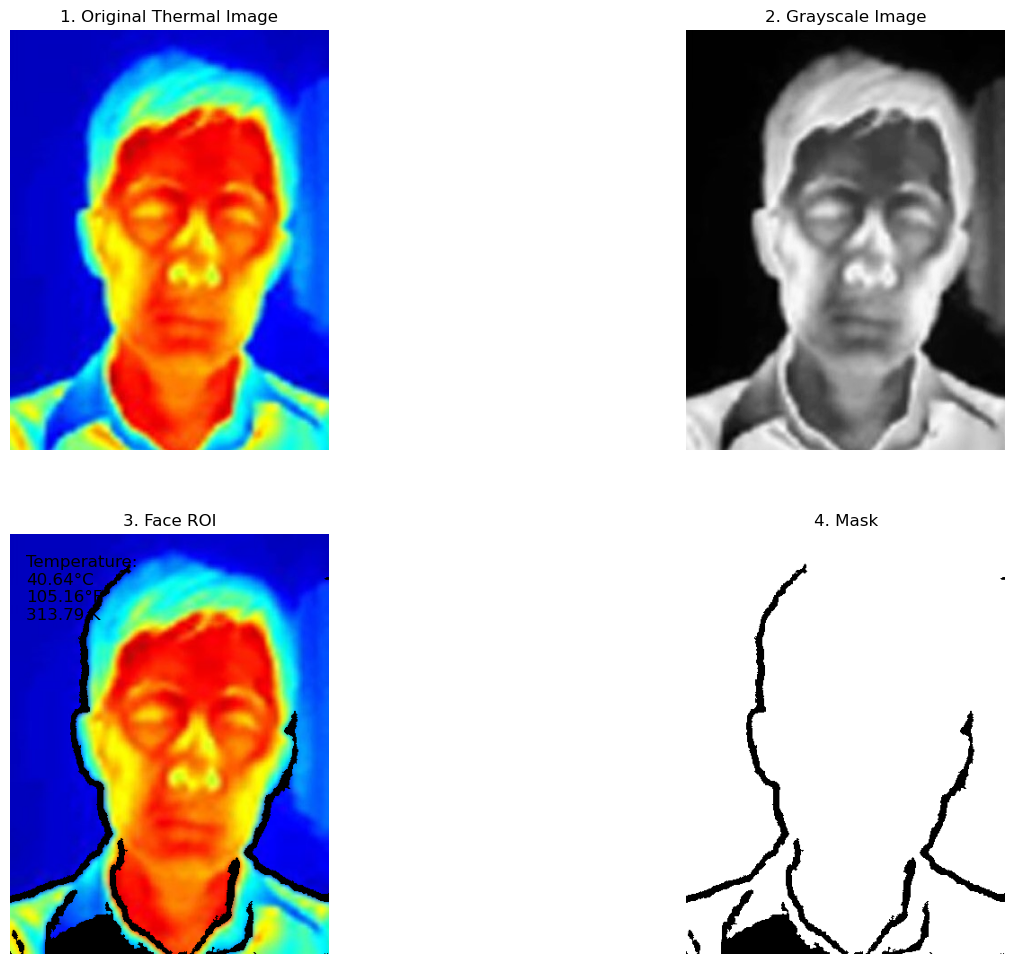

Temperature in Celsius: 40.6448785126089
Temperature in Fahrenheit: 105.16078132269601
Temperature in Kelvin: 313.7948785126089


In [1]:
import sys
sys.path.append('/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages')
import cv2
import numpy as np
import matplotlib.pyplot as plt

def calculate_face_roi_temperature(thermal_image):
    # Convert thermal image to grayscale
    gray_image = cv2.cvtColor(thermal_image, cv2.COLOR_BGR2GRAY)
    
    # Apply Gaussian blur to reduce noise
    blurred = cv2.GaussianBlur(gray_image, (5, 5), 0)
    
    # Thresholding to remove black spots using adaptive thresholding
    thresholded = cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2)
    
    # Find contours of the remaining areas
    contours, _ = cv2.findContours(thresholded, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    # Get the contour with the largest area (assumed to be the face)
    max_contour = max(contours, key=cv2.contourArea)
    
    # Create a mask for the face region
    mask = np.zeros_like(gray_image)
    cv2.drawContours(mask, [max_contour], -1, (255), thickness=cv2.FILLED)
    
    # Bitwise AND operation to get the face-shaped ROI
    face_roi = cv2.bitwise_and(thermal_image, thermal_image, mask=mask)

    #calibrated value of Thermal Image Camera
    cal_val = 90   #75 for data set image, 90 for fever image
    
    # Calculate the mean temperature of the ROI
    roi_temperature = np.mean(face_roi[np.nonzero(face_roi)]) - cal_val
    
    return roi_temperature, gray_image, face_roi, mask

# Example usage
thermal_image = cv2.imread('F:/Thermal_images/Thermal_Image_Fever.jpg')  # Replace 'thermal_image.jpeg' with the correct path to your thermal image

# Calculate ROI temperature and extract grayscale image, face ROI, and mask
roi_temperature, gray_image, face_roi, mask = calculate_face_roi_temperature(thermal_image)

# Convert temperature to Fahrenheit and Kelvin
temperature_fahrenheit = (roi_temperature * 9/5) + 32
temperature_kelvin = roi_temperature + 273.15

# Display images
plt.figure(figsize=(16, 12))

# Original Thermal Image
plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(thermal_image, cv2.COLOR_BGR2RGB))
plt.title('1. Original Thermal Image')
plt.axis('off')

# Grayscale Image
plt.subplot(2, 2, 2)
plt.imshow(gray_image, cmap='gray')
plt.title('2. Grayscale Image')
plt.axis('off')

# Face ROI
plt.subplot(2, 2, 3)
plt.imshow(cv2.cvtColor(face_roi, cv2.COLOR_BGR2RGB))
plt.title('3. Face ROI')
plt.axis('off')
plt.text(0.05, 0.95, f'Temperature:\n{roi_temperature:.2f}°C\n{temperature_fahrenheit:.2f}°F\n{temperature_kelvin:.2f} K', 
         fontsize=12, color='black', transform=plt.gca().transAxes, verticalalignment='top')

# Mask
plt.subplot(2, 2, 4)
plt.imshow(mask, cmap='gray')
plt.title('4. Mask')
plt.axis('off')

plt.show()

# Print temperatures
print("Temperature in Celsius:", roi_temperature)
print("Temperature in Fahrenheit:", temperature_fahrenheit)
print("Temperature in Kelvin:", temperature_kelvin)

